# Задание 4.16
## Две точки в эллипсе (метод Монте-Карло)

### Условие:
В области, ограниченной эллипсом $\Bigl(\dfrac{u}{23}\Bigr)^2+\Bigl(\dfrac v6\Bigr)^2=1$, случайно выбираются две точки. $A$ — расстояние между точками меньше 9,2; $B$ — координаты первой точки больше 0, а координаты второй точки меньше 0. Найдите методом Монте-Карло: 1) $\mathbb P(A)$; 2) $\mathbb P(A|B)$ (100 000 пар точек).

### Метод:
**Равномерная точка в эллипсе** с полуосями $a=23$, $b=6$: берём равномерную точку единичного круга ($r=\sqrt{\xi}$, $\varphi=2\pi\eta$ — корень нужен, чтобы плотность была постоянной) и растягиваем: $u=a\,r\cos\varphi$, $v=b\,r\sin\varphi$ (аффинное преобразование сохраняет равномерность). Событие $B$ — «первая точка в первой четверти, вторая — в третьей»; по симметрии $\mathbb P(B)=\frac14\cdot\frac14=\frac1{16}$, поэтому из 100 000 пар в условие $B$ попадает около 6 250 — оценка $\mathbb P(A|B)=\dfrac{N(A\cap B)}{N(B)}$ имеет бо́льшую погрешность (≈ 0,003).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

In [2]:
def points_in_ellipse(n, a=23.0, b=6.0):
    r = np.sqrt(rng.random(n)); phi = 2*np.pi*rng.random(n)         # равномерная точка в круге, затем растяжение в a и b раз
    return a*r*np.cos(phi), b*r*np.sin(phi)

N = 100_000
u1, v1 = points_in_ellipse(N); u2, v2 = points_in_ellipse(N)
A = np.hypot(u1 - u2, v1 - v2) < 9.2                              # расстояние меньше 9.2
B = (u1 > 0) & (v1 > 0) & (u2 < 0) & (v2 < 0)                     # первая точка в I четверти, вторая — в III
P_A_mc = A.mean(); P_AB_mc = (A & B).sum()/B.sum()
print(f'N = {N}: N(A) = {A.sum()}, N(B) = {B.sum()} (ожидается ≈ N/16 = {N//16}), N(A∩B) = {(A & B).sum()}')
print(f'1) P(A)   ≈ {P_A_mc:.4f}  →  {P_A_mc:.2f}')
print(f'2) P(A|B) ≈ {P_AB_mc:.4f}  →  {P_AB_mc:.2f}')

N = 100000: N(A) = 35037, N(B) = 6251 (ожидается ≈ N/16 = 6250), N(A∩B) = 412
1) P(A)   ≈ 0.3504  →  0.35
2) P(A|B) ≈ 0.0659  →  0.07


### Проверка большой выборкой ($2\cdot10^7$ пар, порциями)

In [3]:
tot = nA = nB = nAB = 0
for _ in range(10):
    m = 2_000_000
    p1, q1 = points_in_ellipse(m); p2, q2 = points_in_ellipse(m)
    a_ = np.hypot(p1 - p2, q1 - q2) < 9.2; b_ = (p1 > 0) & (q1 > 0) & (p2 < 0) & (q2 < 0)
    tot += m; nA += a_.sum(); nB += b_.sum(); nAB += (a_ & b_).sum()
P_A_ref, P_cond_ref = nA/tot, nAB/nB
print(f'эталон (2·10^7 пар): P(A) = {P_A_ref:.5f},  P(B) = {nB/tot:.5f} (теория 0.0625),  P(A|B) = {P_cond_ref:.5f}')

эталон (2·10^7 пар): P(A) = 0.35084,  P(B) = 0.06258 (теория 0.0625),  P(A|B) = 0.06833


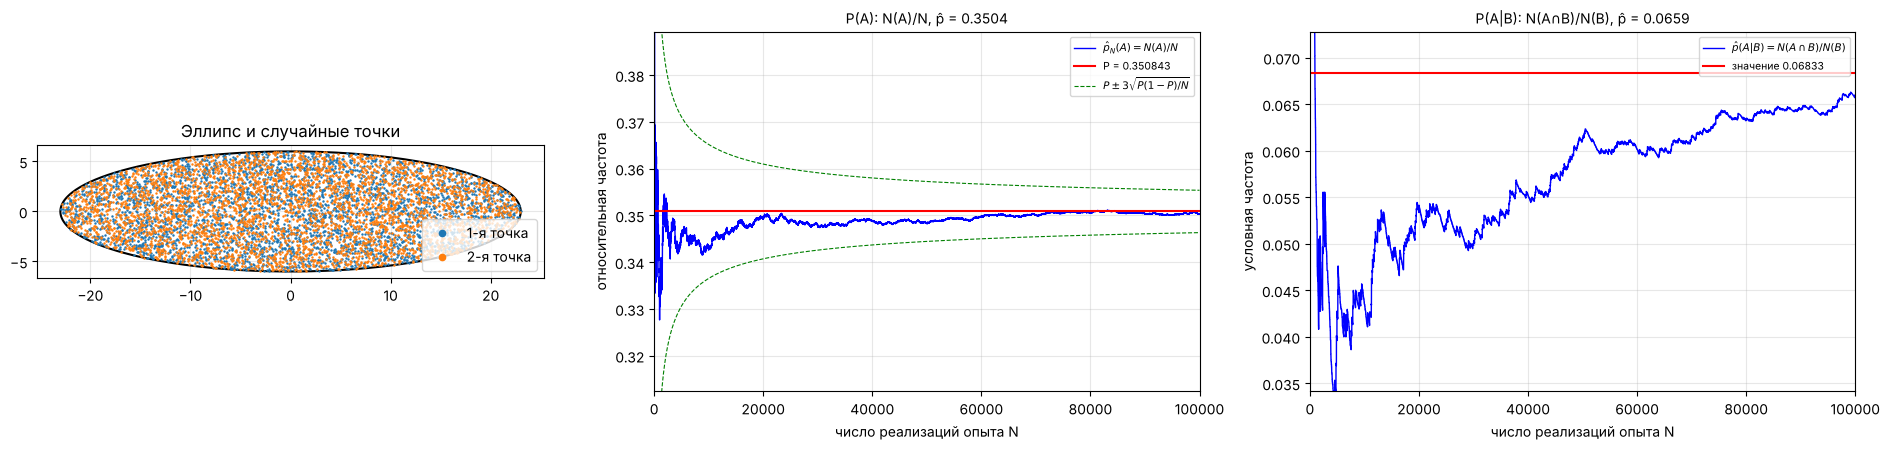

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(19, 4.6), gridspec_kw={'width_ratios': [1.3, 1.4, 1.4]})
t = np.linspace(0, 2*np.pi, 400); axs[0].plot(23*np.cos(t), 6*np.sin(t), 'k-')
k = 4000; axs[0].plot(u1[:k], v1[:k], '.', ms=1.5, c='tab:blue', label='1-я точка'); axs[0].plot(u2[:k], v2[:k], '.', ms=1.5, c='tab:orange', label='2-я точка')
axs[0].set_aspect('equal'); axs[0].legend(markerscale=6); axs[0].set_title('Эллипс и случайные точки'); axs[0].grid(alpha=0.3)
plot_frequency(axs[1], A, P_A_ref, f'P(A): N(A)/N, p̂ = {P_A_mc:.4f}')
plot_conditional(axs[2], A & B, B, P_cond_ref, f'P(A|B): N(A∩B)/N(B), p̂ = {P_AB_mc:.4f}')
plt.tight_layout(); plt.savefig('task_4_16.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
1) $\mathbb P(A)\approx0{,}35$; 2) $\mathbb P(A|B)\approx0{,}07$ (эталонная оценка по $2\cdot10^7$ пар: $0{,}351$ и $0{,}068$; с одним знаком — $0{,}4$ и $0{,}07$).